### snapshot ensemble

In [140]:
# Import necessary libraries
import os
import sys
# Add the utils folder to the system path so we can import custom modules
sys.path.append(os.path.abspath(os.path.join("../..")))
import matplotlib.pyplot as plt
import torch
import numpy as np
import torch.nn as nn
import pandas as pd
from utils.reproducibility_utils import seed_everything
from utils.data_loading import load_data, load_test_data, feature_names

# Set the plotting style for better-looking visualizations
plt.style.available
plt.style.use('seaborn-v0_8')

In [141]:
# Set random seed for reproducibility across runs
# This ensures that your results will be the same every time you run the notebook
seed_everything(42)  # for reproducibility

In [142]:
print("Loading train data...")
train_dataloader, val_dataloader, pipeline = load_data(
    train_path = "../../datasets_challenge/train",  # Path to training data
    train_ratio = 0.98,  # Use 98% for training, 2% for validation 99% gave good result 
    batchsize = 64,  # Number of samples per batch
    # columns_to_standardize = feature_names,  # Option to specify which columns to standardize
    columns_to_drop = ["sideSlip", "vyCG", "time", "longitude","latitude"],  # Remove these from features
    sequence_length = 20,  # Number of time steps in each sequence (t-19 to t0)
    threshold = True,  # Enable velocity thresholding
    threshold_value = 3.0,  # Only keep samples where vehicle speed > 3 m/s
    threshold_column = "vxCG",  # Column to apply threshold on (longitudinal velocity)
    target = "sideSlip",  # The variable we want to predict
    scaling = True,  # Apply standardization to features
    seed = 42,  # Random seed for train/val split
)

Loading train data...
../../datasets_challenge/train\train_part_001.csv
../../datasets_challenge/train\train_part_002.csv
../../datasets_challenge/train\train_part_003.csv
../../datasets_challenge/train\train_part_004.csv
../../datasets_challenge/train\train_part_005.csv
../../datasets_challenge/train\train_part_006.csv
../../datasets_challenge/train\train_part_007.csv
../../datasets_challenge/train\train_part_008.csv
../../datasets_challenge/train\train_part_009.csv
../../datasets_challenge/train\train_part_010.csv
../../datasets_challenge/train\train_part_011.csv
../../datasets_challenge/train\train_part_012.csv
../../datasets_challenge/train\train_part_013.csv
../../datasets_challenge/train\train_part_014.csv
../../datasets_challenge/train\train_part_015.csv
../../datasets_challenge/train\train_part_016.csv
../../datasets_challenge/train\train_part_017.csv
../../datasets_challenge/train\train_part_018.csv
../../datasets_challenge/train\train_part_019.csv
../../datasets_challenge/tra

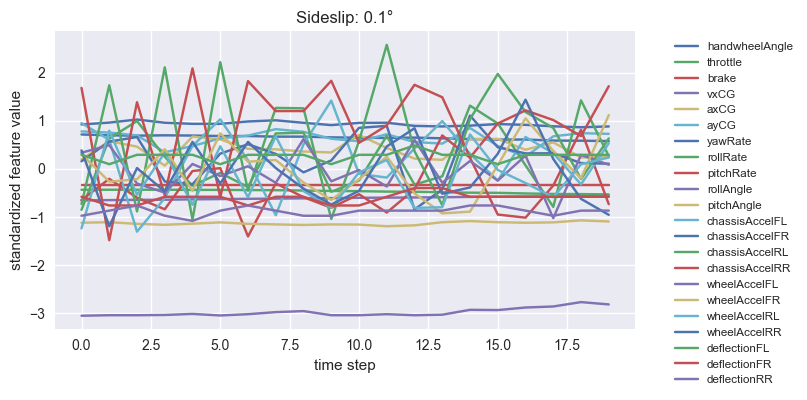

In [143]:
# Get one batch of data from the training dataloader
X, y = next(iter(train_dataloader))

# Visualize the first sample in the batch
plt.figure(figsize=(8,4))
plt.plot(X[0,:,:], label=feature_names)  # Plot all 22 features over 20 time steps
plt.title("Sideslip: "+str(round(y[0].item(),2))+"°")  # Show the target value
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')
plt.tight_layout()
plt.xlabel("time step")
plt.ylabel("standardized feature value")
plt.show()

In [144]:
snapshot_epochs = [10, 20, 30, 40]   # You can adjust these
snapshot_paths = []



In [145]:
class RNN(nn.Module):
    """
    Recurrent Neural Network for sideslip angle prediction.
    
    Architecture:
    1. RNN Layer - Processes sequential input
    2. Fully Connected Layer - Transforms RNN output
    3. Output Layer - Produces final prediction
    
    Dropout layers are included to prevent overfitting.
    """
    def __init__(self, input_size, output_size=1, rnn_units=28, fc_units=28, 
                 activation_fct=nn.ReLU(), dropout=[0.0, 0, 0], rnn_nonlinearity='relu'):
        super(RNN, self).__init__()
        
        # RNN layer: processes the sequence and captures temporal dependencies
        self.rnn_layer = nn.RNN(input_size=input_size, hidden_size=rnn_units, 
                                num_layers=1, nonlinearity=rnn_nonlinearity, batch_first=True)
        
        # Fully connected layers for processing RNN output
        self.fc = nn.Linear(rnn_units, fc_units)
        self.output_layer = nn.Linear(fc_units, output_size)
        
        # Dropout layers to prevent overfitting (randomly zeros out neurons during training)
        self.dropout1 = nn.Dropout(dropout[0])  # Applied to input
        self.dropout2 = nn.Dropout(dropout[1])  # Applied after RNN
        self.dropout3 = nn.Dropout(dropout[2])  # Applied after FC layer
        
        self.activation_fct = activation_fct
 
    def forward(self, x):
        # x shape: (batch_size, sequence_length, input_size)
        x = self.dropout1(x)
        
        # Process sequence through RNN
        x, _ = self.rnn_layer(x)  # Output shape: (batch_size, sequence_length, rnn_units)
        
        # Take only the last time step's output (t0)
        x = x[:, -1, :]  # Shape: (batch_size, rnn_units)
        
        x = self.dropout2(x)
        x = self.activation_fct(self.fc(x))  # Apply fully connected layer with activation
        x = self.dropout3(x)
        x = self.output_layer(x)  # Final prediction
        
        return x

In [146]:
# Set device for computation (CPU or GPU)
device = "cpu"  # Change to "cuda" if you have a GPU available

# Model hyperparameters
input_size = X.shape[2]  # Number of features (22 in this case)
rnn_units = 64  # Number of units in RNN hidden state
fc_units = 64  # Number of units in fully connected layer
output_size = 1  # Single output (sideslip angle)
lr = 0.0003  # Learning rate for optimizer

# Initialize the model with specified architecture
model = RNN(
    input_size=input_size, 
    output_size=output_size,
    rnn_units=rnn_units,
    fc_units=fc_units,
    dropout=[0.0, 0.0, 0.0]  # Dropout rates for [input, after_rnn, after_fc]
).to(device)

# Define loss function and optimizer
criterion = nn.L1Loss()  # Mean Absolute Error (MAE) - measures average prediction error
optimizer = torch.optim.Adam(model.parameters(), lr=lr)  # Adam optimizer for weight updates

In [147]:
# Training configuration
num_epochs = 50 # 60 gave good result
early_stop_thresh = 10
best_loss = np.inf
best_epoch = -1

train_curve = []
val_curve = []

for epoch in range(num_epochs):
    running_loss = 0
    
    # ========== TRAINING ==========
    model.train()
    for step, (x, y) in enumerate(train_dataloader):
        X, y = x.to(device), y.to(device).reshape(-1, 1)

        optimizer.zero_grad()
        pred = model(X)
        loss = criterion(pred, y)
        running_loss += loss.item()
        loss.backward()
        optimizer.step()

    avg_train_loss = running_loss / (step + 1)
    train_curve.append(avg_train_loss)

    # ========== VALIDATION ==========
    if val_dataloader is not None:
        model.eval()
        running_val = 0
        with torch.no_grad():
            for val_step, (xv, yv) in enumerate(val_dataloader):
                Xv, yv = xv.to(device), yv.to(device).reshape(-1, 1)
                vloss = criterion(model(Xv), yv)
                running_val += vloss.item()

        avg_val_loss = running_val / (val_step + 1)
        val_curve.append(avg_val_loss)

        print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {avg_train_loss:.5f} "
              f"| Val Loss: {avg_val_loss:.5f}", end="")

        # → SAVE BEST MODEL
        if avg_val_loss < best_loss:
            best_loss = avg_val_loss
            best_epoch = epoch
            torch.save({
                "model_state_dict": model.state_dict(),
                "epoch": epoch,
                "val_loss": avg_val_loss
            }, "best_model.pth")
            print(" → New best!")
        elif epoch - best_epoch > early_stop_thresh:
            print(" → Early stopping!")
            break
        else:
            print("")
    
    else:
        print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {avg_train_loss:.5f}")

    # ========== SNAPSHOT SAVE ==========
    if (epoch + 1) in snapshot_epochs:
        snap_path = f"snapshot_{epoch+1}.pth"
        torch.save(model.state_dict(), snap_path)
        snapshot_paths.append(snap_path)
        print(f"✓ Saved snapshot model: {snap_path}")
        
        
if best_epoch != -1:
    checkpoint = torch.load("best_model.pth")
    model.load_state_dict(checkpoint["model_state_dict"])
    print(f"\n✓ Best model loaded (epoch {best_epoch+1}, val loss {best_loss:.5f})")
else:
    print("\n⚠ No validation improvement, using last model.")
print("Training complete.")

Epoch 1/50 | Train Loss: 0.27533 | Val Loss: 0.19839 → New best!
Epoch 2/50 | Train Loss: 0.19113 | Val Loss: 0.18011 → New best!
Epoch 3/50 | Train Loss: 0.17636 | Val Loss: 0.17108 → New best!
Epoch 4/50 | Train Loss: 0.16725 | Val Loss: 0.15698 → New best!
Epoch 5/50 | Train Loss: 0.16230 | Val Loss: 0.15560 → New best!
Epoch 6/50 | Train Loss: 0.15795 | Val Loss: 0.15758
Epoch 7/50 | Train Loss: 0.15485 | Val Loss: 0.15562
Epoch 8/50 | Train Loss: 0.15233 | Val Loss: 0.15427 → New best!
Epoch 9/50 | Train Loss: 0.15053 | Val Loss: 0.15926
Epoch 10/50 | Train Loss: 0.14870 | Val Loss: 0.14694 → New best!
✓ Saved snapshot model: snapshot_10.pth
Epoch 11/50 | Train Loss: 0.14735 | Val Loss: 0.14355 → New best!
Epoch 12/50 | Train Loss: 0.14524 | Val Loss: 0.14168 → New best!
Epoch 13/50 | Train Loss: 0.14399 | Val Loss: 0.14831
Epoch 14/50 | Train Loss: 0.14306 | Val Loss: 0.13666 → New best!
Epoch 15/50 | Train Loss: 0.14110 | Val Loss: 0.14005
Epoch 16/50 | Train Loss: 0.13951 | Val

In [153]:
def snapshot_ensemble_predict(test_loader, snapshot_paths):
    preds_all = []

    for path in snapshot_paths:
        model = RNN(
            input_size=test_loader.dataset[0][0].shape[1],
            rnn_units=64,
            fc_units=64,
            dropout=[0,0,0]
        ).to(device)

        model.load_state_dict(torch.load(path, map_location=device))
        model.eval()

        preds = []
        with torch.no_grad():
            for X, _ in test_loader:
                X = X.to(device)
                preds.append(model(X).cpu())

        preds_all.append(torch.cat(preds))

    preds_all = torch.stack(preds_all)   # shape: (num_snapshots, N, 1)
    final_preds = preds_all.mean(dim=0)  # average snapshots

    return final_preds


In [149]:
# Load complete training data (unshuffled) for visualization
# This uses the same preprocessing pipeline to ensure consistency
train_dataloader_unshuffled = load_test_data(
    test_path="../../datasets_challenge/train",
    batchsize=64,
    pipeline=pipeline,  # Use the same preprocessing as training
    load_anonymized_data=False  # We have ground truth for training data
)

../../datasets_challenge/train\train_part_001.csv
../../datasets_challenge/train\train_part_002.csv
../../datasets_challenge/train\train_part_003.csv
../../datasets_challenge/train\train_part_004.csv
../../datasets_challenge/train\train_part_005.csv
../../datasets_challenge/train\train_part_006.csv
../../datasets_challenge/train\train_part_007.csv
../../datasets_challenge/train\train_part_008.csv
../../datasets_challenge/train\train_part_009.csv
../../datasets_challenge/train\train_part_010.csv
../../datasets_challenge/train\train_part_011.csv
../../datasets_challenge/train\train_part_012.csv
../../datasets_challenge/train\train_part_013.csv
../../datasets_challenge/train\train_part_014.csv
../../datasets_challenge/train\train_part_015.csv
../../datasets_challenge/train\train_part_016.csv
../../datasets_challenge/train\train_part_017.csv
../../datasets_challenge/train\train_part_018.csv
../../datasets_challenge/train\train_part_019.csv
../../datasets_challenge/train\train_part_020.csv


In [154]:
import plotly.graph_objects as go

# Set model to evaluation mode
model.eval()

# Storage for predictions and ground truth
total_loss = 0  
preds = []
ground_truths = []

# Generate predictions for all training data
with torch.no_grad():
    for step, (x, y) in enumerate(train_dataloader_unshuffled):
        X, y = x.to(device), y.to(device).reshape([len(y), 1])

        pred = model(X)
        loss = criterion(pred, y)
        total_loss += loss.item()
        
        # Store predictions and ground truth
        preds.append(pred.reshape(-1).cpu().numpy())
        ground_truths.append(y.reshape(-1).cpu().numpy())

    print(f"Avg. Loss: {total_loss/step}")
    
    # Concatenate all batches into single arrays
    ground_truths = np.concatenate(ground_truths)
    preds = np.concatenate(preds)

# Create interactive plot
fig = go.Figure()
fig.add_trace(go.Scatter(y=ground_truths, mode='lines', name='truth', line=dict(color='blue')))
fig.add_trace(go.Scatter(y=preds.flatten(), mode='lines', name='pred', line=dict(color='red'), opacity=0.8))
fig.update_layout(
    title='Ground Truth vs Predictions',
    xaxis_title='Sample Index',
    yaxis_title='Sideslip Angle (degrees)',
    width=1200,
    height=500
)
fig.show()

Avg. Loss: 0.12039956244710086


In [155]:
print("\nLoading test data...")
test_dataloader = load_test_data(test_path = "../../datasets_challenge/test",
                                 batchsize = 64,
                                 pipeline = pipeline, 
                                 load_anonymized_data=True)


Loading test data...
../../datasets_challenge/test\test_part_001.csv
../../datasets_challenge/test\test_part_002.csv
../../datasets_challenge/test\test_part_003.csv
../../datasets_challenge/test\test_part_004.csv
../../datasets_challenge/test\test_part_005.csv
../../datasets_challenge/test\test_part_006.csv
../../datasets_challenge/test\test_part_007.csv
../../datasets_challenge/test\test_part_008.csv
../../datasets_challenge/test\test_part_009.csv
../../datasets_challenge/test\test_part_010.csv
../../datasets_challenge/test\test_part_011.csv


In [156]:
# -----------------------------------------
# SNAPSHOT ENSEMBLE PREDICTION
# -----------------------------------------
print("\nRunning Snapshot Ensemble prediction...")

final_pred_tensor = snapshot_ensemble_predict(test_dataloader, snapshot_paths)
snapshot_pred = final_pred_tensor.reshape(-1).numpy()

print("✓ Snapshot Ensemble prediction complete.")

# Save submission
y_pred = pd.DataFrame({"predicted_sideslip": snapshot_pred})
y_pred["id"] = range(len(snapshot_pred))

y_pred.to_csv("predictions_snapshot_ensemble.csv", index=False)
print("✓ Saved 'predictions_snapshot_ensemble.csv'")



Running Snapshot Ensemble prediction...
✓ Snapshot Ensemble prediction complete.
✓ Saved 'predictions_snapshot_ensemble.csv'
